1. Load the dataset in Python environment

In [86]:
#step 1 -Load the dataset in Python environment

import pandas as pd
df=pd.read_csv("/content/train_loan.csv")
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [88]:
df.duplicated().sum() #no duplicates

np.int64(0)

In [89]:
df.isnull().sum()
round(df.isnull().mean()*100,2)  #find missing values

,0
Loan_ID,0.00
Gender,2.12
Married,0.49
Dependents,2.44
Education,0.00
Self_Employed,5.21
ApplicantIncome,0.00
CoapplicantIncome,0.00
LoanAmount,3.58
Loan_Amount_Term,2.28


2. Perform different preprocessing steps


a. Missing value handling

In [90]:

# Numerical columns: fill with median using imputation
df["LoanAmount"].median()
df["LoanAmount"].fillna(df["LoanAmount"].median(),inplace=True)
df["LoanAmount"].isnull().sum()


/tmp/ipykernel_876/1650702112.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["LoanAmount"].fillna(df["LoanAmount"].median(),inplace=True)


np.int64(0)

In [91]:
df['Loan_Amount_Term'].median()
df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].median(),inplace=True)
df['Loan_Amount_Term'].isnull().sum()

/tmp/ipykernel_876/1770560563.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].median(),inplace=True)


np.int64(0)

In [92]:
df["Credit_History"].mode()
df["Credit_History"].fillna(df["Credit_History"].mode()[0],inplace=True)
df["Credit_History"].isnull().sum()

/tmp/ipykernel_876/3158163248.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Credit_History"].fillna(df["Credit_History"].mode()[0],inplace=True)


np.int64(0)

In [93]:
df1=df.dropna(subset=["Married"])
df1.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,0
Dependents,12
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [94]:
#fill catagorical coloumns using mode

df1["Gender"].fillna(df1["Gender"].mode()[0],inplace=True)
df1["Gender"].isnull().sum()

/tmp/ipykernel_876/2908063535.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df1["Gender"].fillna(df1["Gender"].mode()[0],inplace=True)
/tmp/ipykernel_876/2908063535.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1["Gender"].fillna(df1["Gender"].mode()[0],inplace=True)


np.int64(0)

In [95]:
df1["Dependents"].fillna(df1["Dependents"].mode()[0],inplace=True)
df1["Dependents"].isnull().sum()


/tmp/ipykernel_876/1961010007.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df1["Dependents"].fillna(df1["Dependents"].mode()[0],inplace=True)
/tmp/ipykernel_876/1961010007.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1["Dependents"].fillna(df1["Dependents"].mode()[0],inplace=True)


np.int64(0)

In [96]:
df1["Self_Employed"].fillna(df1["Self_Employed"].mode()[0],inplace=True)
df1["Self_Employed"].isnull().sum()

/tmp/ipykernel_876/1585423935.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df1["Self_Employed"].fillna(df1["Self_Employed"].mode()[0],inplace=True)
/tmp/ipykernel_876/1585423935.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1["Self_Employed"].fillna(df1["Self_Employed"].mode()[0],inplace=True)


np.int64(0)

In [97]:
df1.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [98]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 611 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            611 non-null    object 
 1   Gender             611 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         611 non-null    object 
 4   Education          611 non-null    object 
 5   Self_Employed      611 non-null    object 
 6   ApplicantIncome    611 non-null    int64  
 7   CoapplicantIncome  611 non-null    float64
 8   LoanAmount         611 non-null    float64
 9   Loan_Amount_Term   611 non-null    float64
 10  Credit_History     611 non-null    float64
 11  Property_Area      611 non-null    object 
 12  Loan_Status        611 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 66.8+ KB


ApplicantIncome


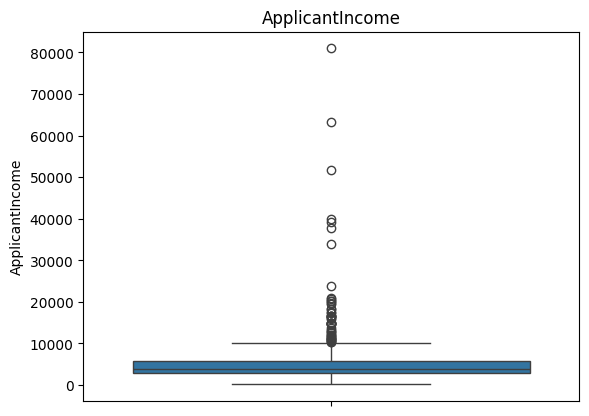

CoapplicantIncome


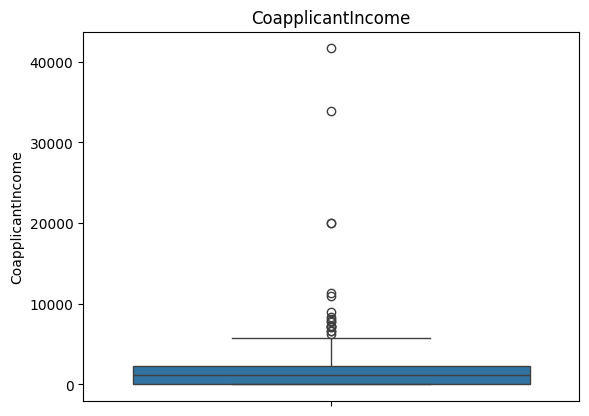

LoanAmount


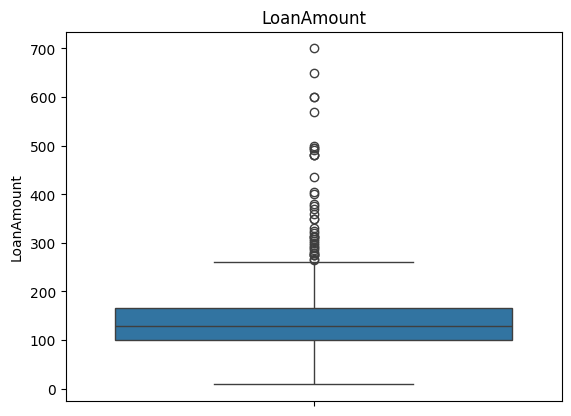

Loan_Amount_Term


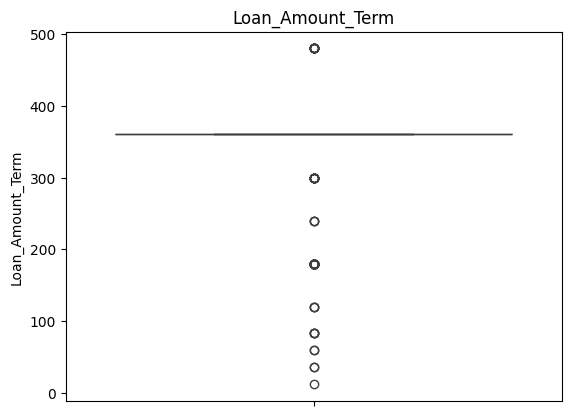

Credit_History


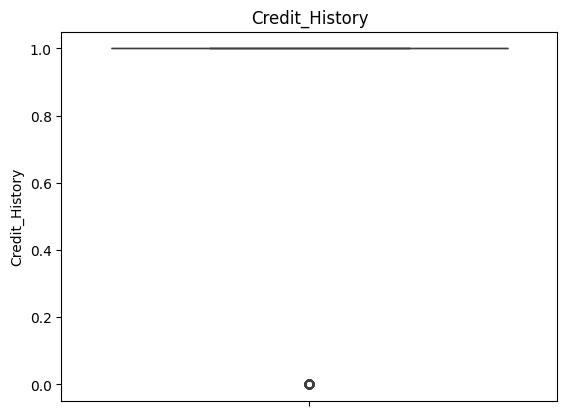

In [99]:
#outliers finding using boxplot

from numpy import number
import matplotlib.pyplot as plt
import seaborn as sns
for i in df1.select_dtypes("number").columns:
  print(i)
  sns.boxplot(df1[i])
  plt.title(i)
  plt.show(i)

6.5353458411074055


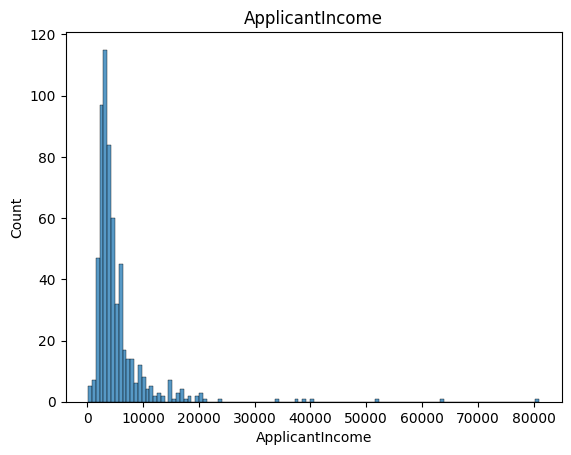

7.479900817988621


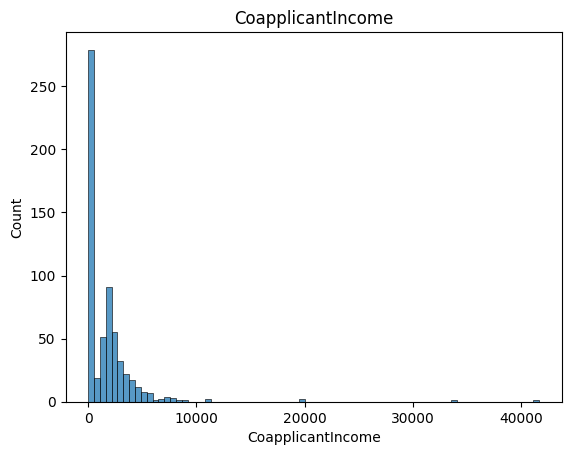

2.7375221027359538


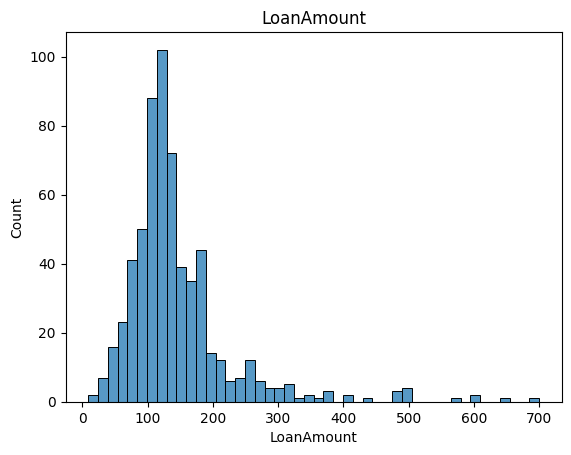

-2.444382352127082


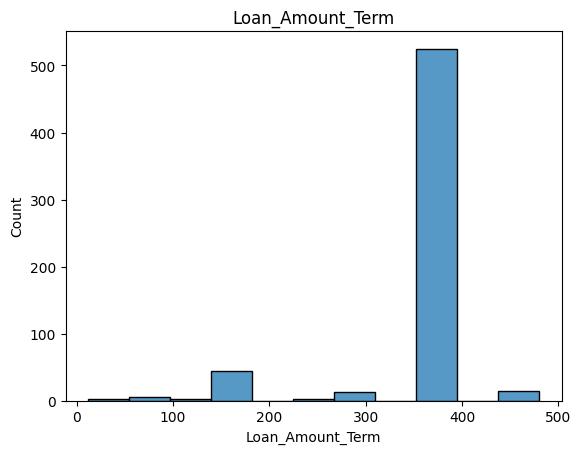

-2.0138442137771073


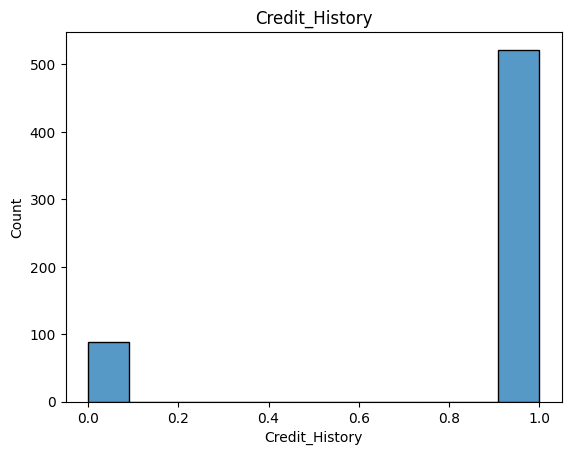

In [100]:
#using hisplot

for i in df1.select_dtypes("number").columns:
  sns.histplot(df1[i])
  plt.title(i)
  print(df1[i].skew())
  plt.show(i)



b,Outlier detection

In [101]:


import pandas as pd
def remove_outliers(df, columns):
    df_filtered = df  # Make a copy of the original DataFrame
    for i in columns:
        Q1 = df[i].quantile(0.25)
        Q3 = df[i].quantile(0.75)
        IQR = Q3 - Q1
        lower_whisker = Q1 - 1.5 * IQR
        upper_whisker = Q3 + 1.5 * IQR
        # Filter out rows where column values are outliers
        df_filtered = df_filtered[(df_filtered[i] >= lower_whisker) & (df_filtered[i] <= upper_whisker)]
    return df_filtered

In [102]:
df2=remove_outliers(df1,["ApplicantIncome","CoapplicantIncome","Loan_Amount_Term","Credit_History","LoanAmount"])#remove outlier

ApplicantIncome


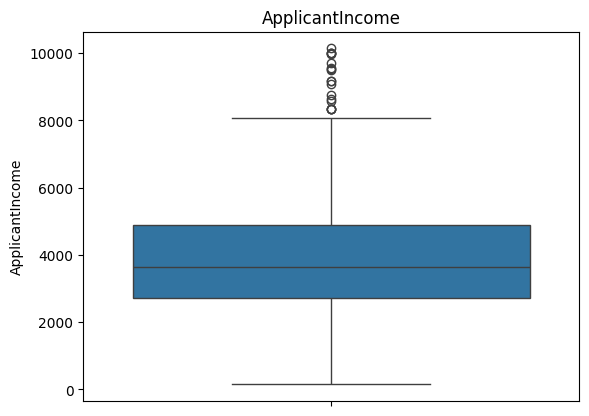

CoapplicantIncome


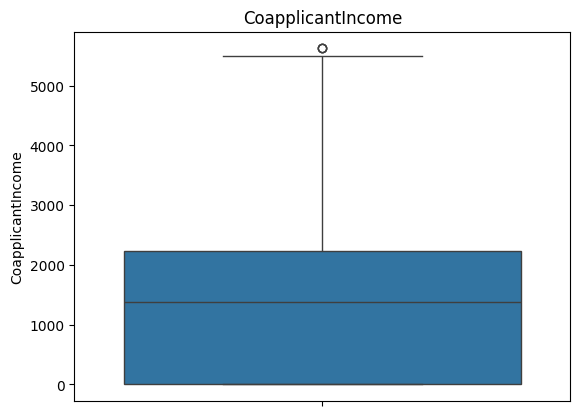

LoanAmount


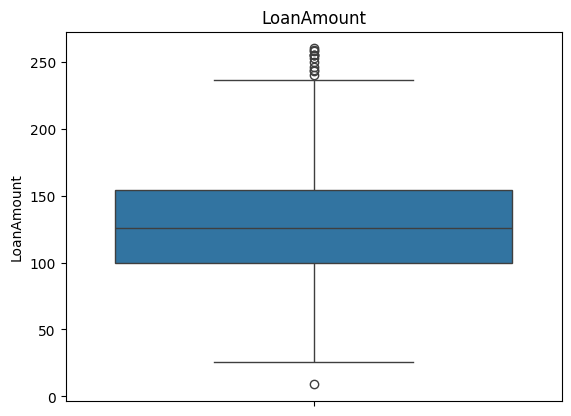

Loan_Amount_Term


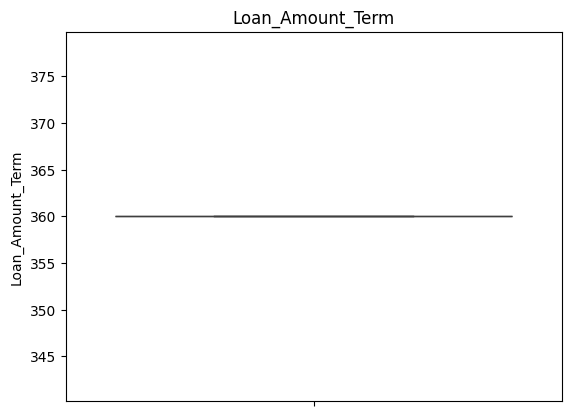

Credit_History


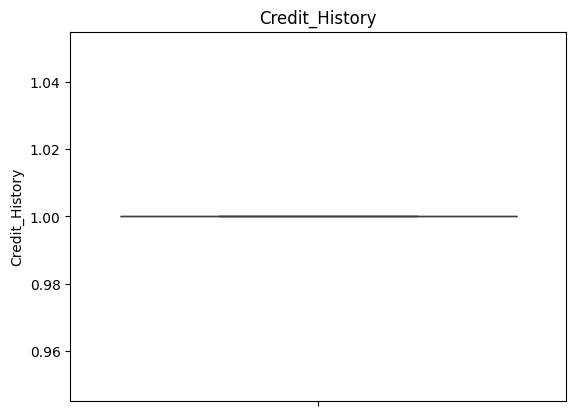

In [103]:
for i in df2.select_dtypes("number").columns:
  print(i)
  sns.boxplot(df2[i])
  plt.title(i)
  plt.show(i)



c. Encoding

In [104]:
df3= pd.get_dummies(
    df2,
    columns=[
        "Gender","Married","Dependents","Education","Self_Employed","Property_Area" ],drop_first=True,dtype=int)
print(df3.head())

    Loan_ID  ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0  LP001002             5849                0.0       128.0             360.0   
1  LP001003             4583             1508.0       128.0             360.0   
2  LP001005             3000                0.0        66.0             360.0   
3  LP001006             2583             2358.0       120.0             360.0   
4  LP001008             6000                0.0       141.0             360.0   

   Credit_History Loan_Status  Gender_Male  Married_Yes  Dependents_1  \
0             1.0           Y            1            0             0   
1             1.0           N            1            1             1   
2             1.0           Y            1            1             0   
3             1.0           Y            1            1             0   
4             1.0           Y            1            0             0   

   Dependents_2  Dependents_3+  Education_Not Graduate  Self_Employed_Yes 

In [105]:
df3.info()
df3

<class 'pandas.core.frame.DataFrame'>
Index: 395 entries, 0 to 612
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Loan_ID                  395 non-null    object 
 1   ApplicantIncome          395 non-null    int64  
 2   CoapplicantIncome        395 non-null    float64
 3   LoanAmount               395 non-null    float64
 4   Loan_Amount_Term         395 non-null    float64
 5   Credit_History           395 non-null    float64
 6   Loan_Status              395 non-null    object 
 7   Gender_Male              395 non-null    int64  
 8   Married_Yes              395 non-null    int64  
 9   Dependents_1             395 non-null    int64  
 10  Dependents_2             395 non-null    int64  
 11  Dependents_3+            395 non-null    int64  
 12  Education_Not Graduate   395 non-null    int64  
 13  Self_Employed_Yes        395 non-null    int64  
 14  Property_Area_Semiurban  395 no

,Loan_ID,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,LP001002,5849,0.0,128.0,360.0,1.0,Y,1,0,0,0,0,0,0,0,1
1,LP001003,4583,1508.0,128.0,360.0,1.0,N,1,1,1,0,0,0,0,0,0
2,LP001005,3000,0.0,66.0,360.0,1.0,Y,1,1,0,0,0,0,1,0,1
3,LP001006,2583,2358.0,120.0,360.0,1.0,Y,1,1,0,0,0,1,0,0,1
4,LP001008,6000,0.0,141.0,360.0,1.0,Y,1,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
607,LP002964,3987,1411.0,157.0,360.0,1.0,Y,1,1,0,1,0,1,0,0,0
608,LP002974,3232,1950.0,108.0,360.0,1.0,Y,1,1,0,0,0,0,0,0,0
609,LP002978,2900,0.0,71.0,360.0,1.0,Y,0,0,0,0,0,0,0,0,0
611,LP002983,8072,240.0,253.0,360.0,1.0,Y,1,1,1,0,0,0,0,0,1


ApplicantIncome
1.1277710008833415


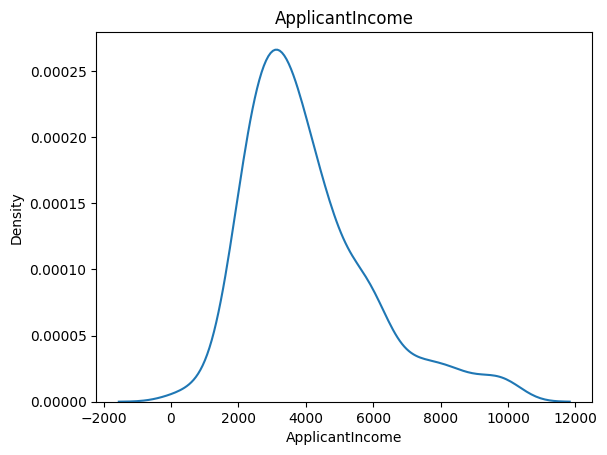

CoapplicantIncome
0.8224749686886336


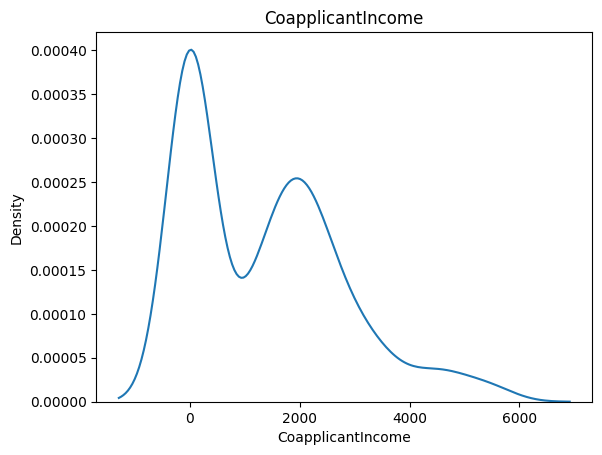

LoanAmount
0.48487537794254687


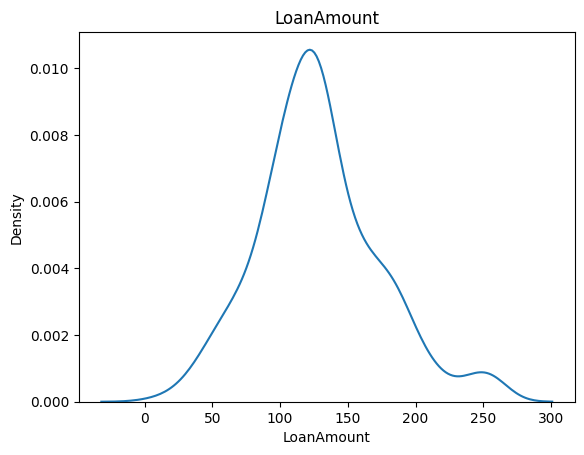

Loan_Amount_Term
0.0


/tmp/ipykernel_876/227821908.py:4: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df3[i])


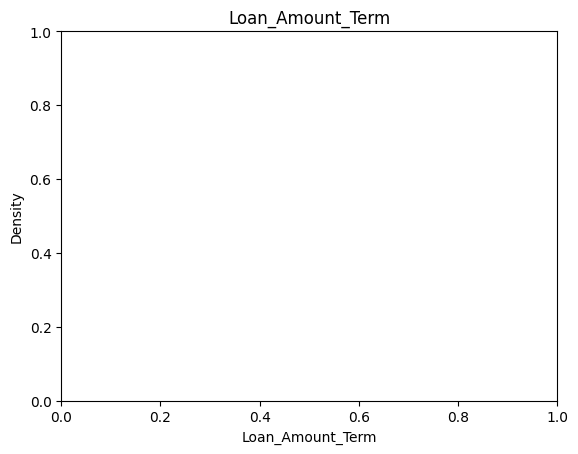

Credit_History


/tmp/ipykernel_876/227821908.py:4: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df3[i])


0.0


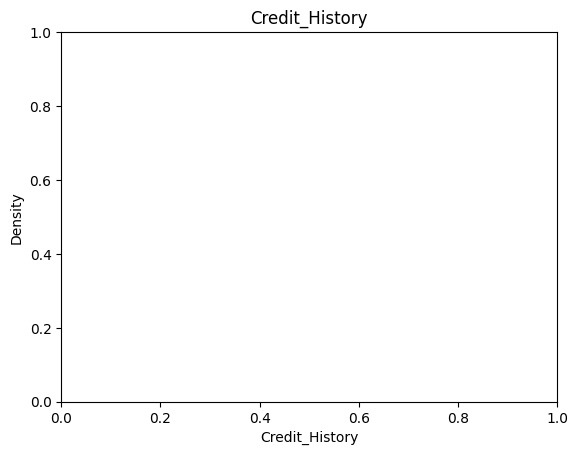

Gender_Male
-1.5666004403466096


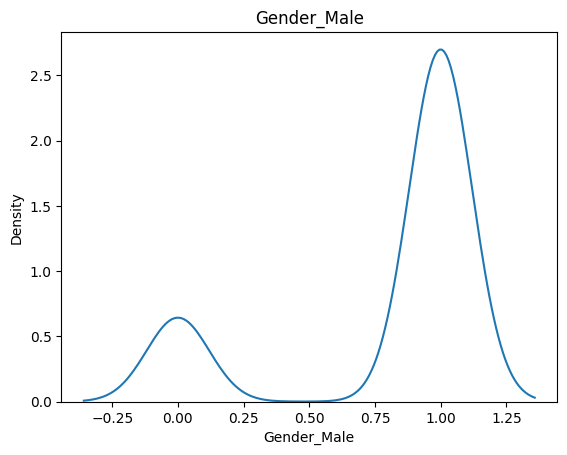

Married_Yes
-0.5993853684312751


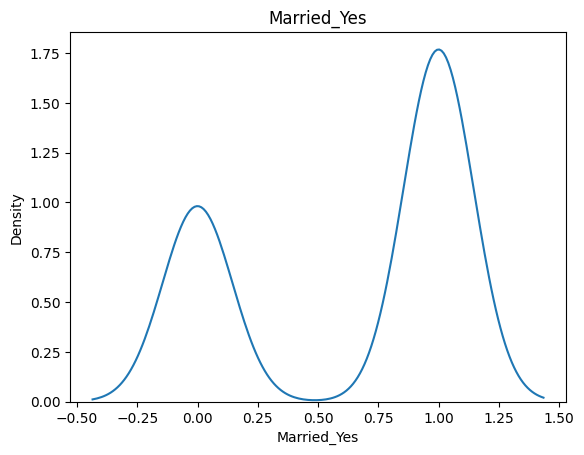

Dependents_1
1.8932389805321361


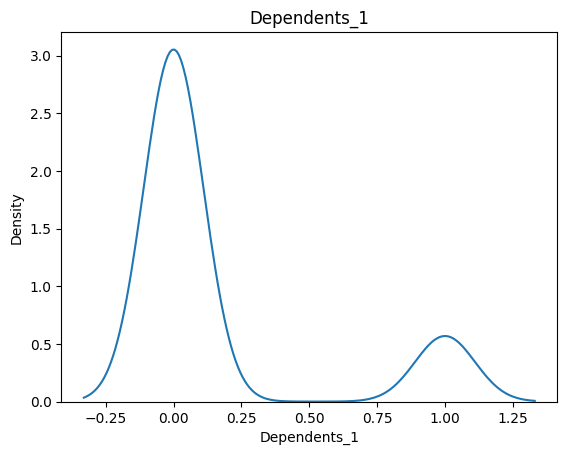

Dependents_2
1.8414561679585655


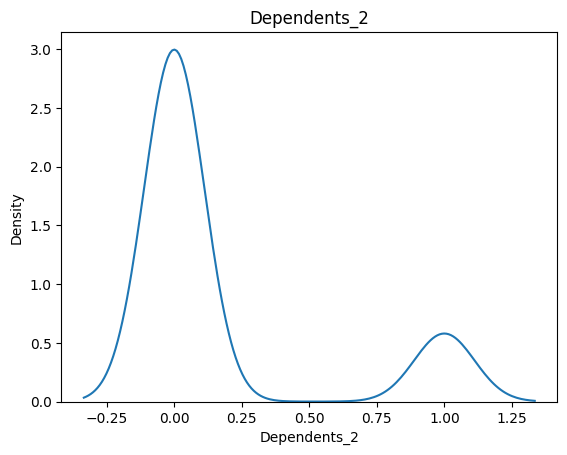

Dependents_3+
3.6008276686960103


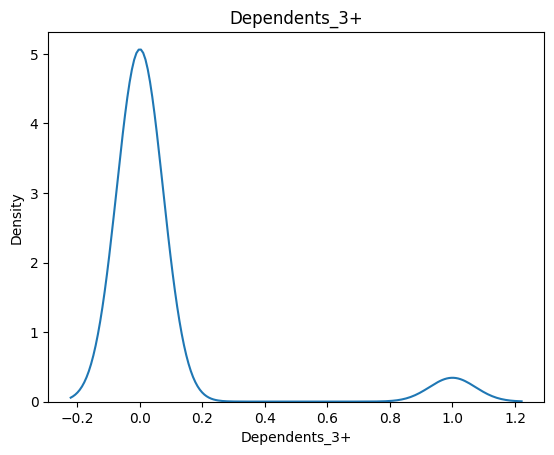

Education_Not Graduate
1.3731896015007161


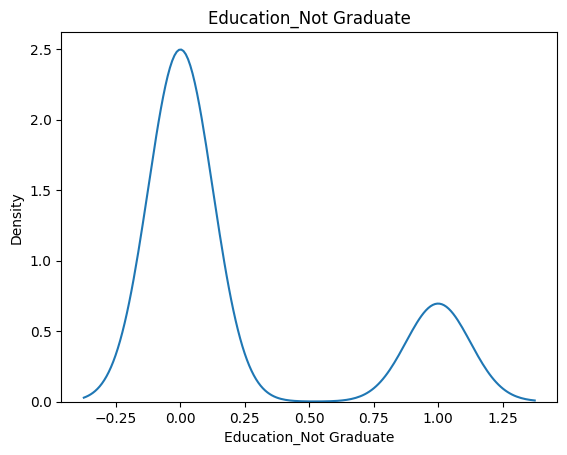

Self_Employed_Yes
2.4005187777566874


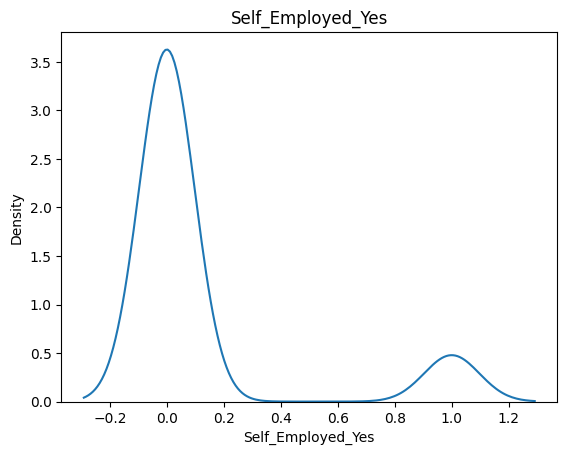

Property_Area_Semiurban
0.4423861930724788


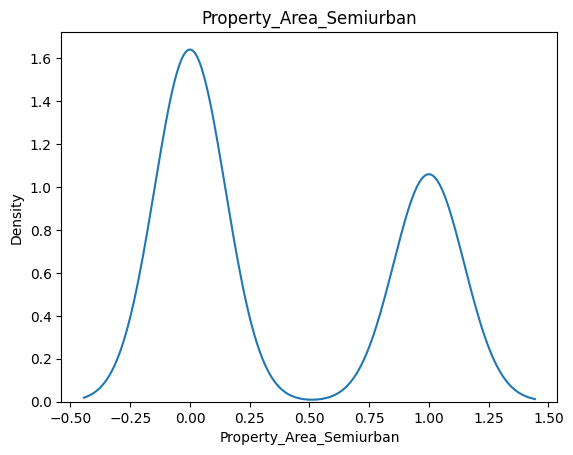

Property_Area_Urban
0.8961168746739859


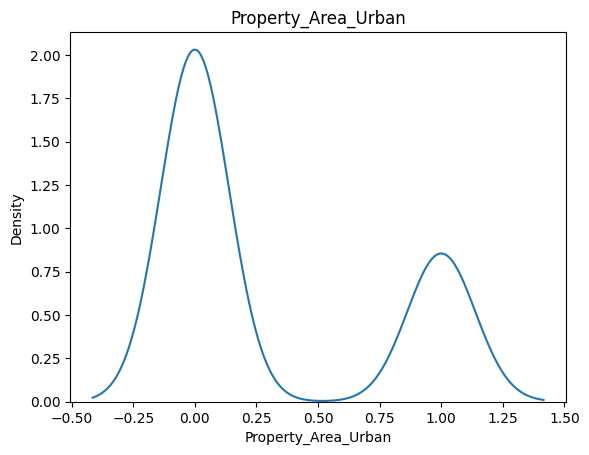

In [106]:
import seaborn as sns
for i in df3.select_dtypes("number").columns:
  print(i)
  sns.kdeplot(df3[i])
  plt.title(i)
  print(df3[i].skew())
  plt.show(i)


In [107]:
pd.DataFrame(df3)

,Loan_ID,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,LP001002,5849,0.0,128.0,360.0,1.0,Y,1,0,0,0,0,0,0,0,1
1,LP001003,4583,1508.0,128.0,360.0,1.0,N,1,1,1,0,0,0,0,0,0
2,LP001005,3000,0.0,66.0,360.0,1.0,Y,1,1,0,0,0,0,1,0,1
3,LP001006,2583,2358.0,120.0,360.0,1.0,Y,1,1,0,0,0,1,0,0,1
4,LP001008,6000,0.0,141.0,360.0,1.0,Y,1,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
607,LP002964,3987,1411.0,157.0,360.0,1.0,Y,1,1,0,1,0,1,0,0,0
608,LP002974,3232,1950.0,108.0,360.0,1.0,Y,1,1,0,0,0,0,0,0,0
609,LP002978,2900,0.0,71.0,360.0,1.0,Y,0,0,0,0,0,0,0,0,0
611,LP002983,8072,240.0,253.0,360.0,1.0,Y,1,1,1,0,0,0,0,0,1


In [110]:
df3[["ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term"]].describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
count,395.000000,395.000000,395.000000,395.0
mean,4059.962025,1354.200304,128.394937,360.0
std,1868.851363,1421.852513,45.079805,0.0
min,150.000000,0.000000,9.000000,360.0
25%,2713.000000,0.000000,100.000000,360.0
50%,3652.000000,1376.000000,126.000000,360.0
75%,4886.000000,2227.500000,154.500000,360.0
max,10139.000000,5625.000000,260.000000,360.0


d. Scaling

In [108]:
from sklearn.preprocessing import StandardScaler

std = StandardScaler()

df5 = pd.DataFrame(std.fit_transform(df3[[ "ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term" ]]),columns=[ "ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term" ])
df5

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,0.958507,-0.953628,-0.008772,0.0
1,0.280226,0.108306,-0.008772,0.0
2,-0.567892,-0.953628,-1.385855,0.0
3,-0.791307,0.706876,-0.186460,0.0
4,1.039408,-0.953628,0.279971,0.0
...,...,...,...,...
390,-0.039091,0.039998,0.635347,0.0
391,-0.443594,0.419562,-0.452992,0.0
392,-0.621469,-0.953628,-1.274800,0.0
393,2.149516,-0.784620,2.767605,0.0


<Axes: xlabel='ApplicantIncome', ylabel='Density'>

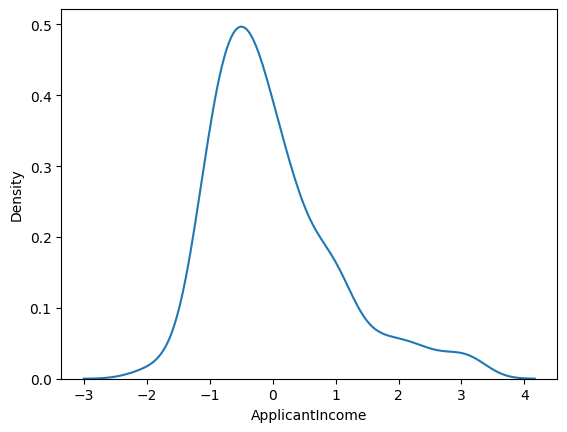

In [112]:
sns.kdeplot(df5["ApplicantIncome"])

3. Give detailed description for each step

Missing value handling: fills missing numerical and categorical values.



Outlier detection: identifies extreme numerical values using IQR and caps them.



Encoding: converts categorical features into numerical columns.



Scaling: standardizes selected numerical features.